# Notebook 03 – How Good Is Our Device-Failure Model?
### Day 4 · Topic 3: Classification Metrics

**Business use case (continued from Notebook 01): NetLink Ops device failure prediction**

We built two models that flag devices likely to fail in the next 30 days. A flagged device gets a **proactive truck-roll** (planned visit or replacement).

- A **missed failure** means an unplanned outage, an emergency call-out, SLA credits and an unhappy customer.
- A **false alarm** means a wasted planned visit: engineer time and fuel, but no outage.

This notebook answers: *How good are the models, really, and how do we explain that to the operations manager?*



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (8, 4.5)

## Setup: Recreate the Same Data and Models as Notebook 01

In [2]:
def make_devices(n=2000, seed=42):
    """Synthetic NetLink Ops device inventory with a 'failed in next 30 days' label."""
    rng = np.random.default_rng(seed)
    device_type = rng.choice(["Router", "Switch", "Firewall"], size=n, p=[0.4, 0.4, 0.2])
    age_years = rng.uniform(0.5, 10, n).round(1)
    firmware_age_months = rng.integers(0, 61, n)
    avg_cpu_util_pct = np.clip(rng.normal(45, 15, n), 5, 98).round(1)
    avg_temp_c = np.clip(rng.normal(42, 6, n), 25, 70).round(1)
    crash_count_90d = rng.poisson(0.2 + 0.12 * age_years)
    port_error_rate_pct = np.clip(rng.exponential(0.6, n), 0, 5).round(2)
    days_since_reboot = rng.integers(1, 1500, n)          # big numbers, little real signal
    site_region = rng.choice(["North", "South", "East", "West"], size=n)  # pure noise

    # Hidden "true" risk recipe (the model never sees this)
    risk_score = (-8.2 + 0.40 * age_years + 0.045 * firmware_age_months
                  + 0.05 * (avg_cpu_util_pct - 45) + 0.16 * (avg_temp_c - 42)
                  + 0.9 * crash_count_90d + 1.2 * port_error_rate_pct
                  + 0.8 * (device_type == "Firewall"))
    prob = 1 / (1 + np.exp(-risk_score))
    failed_next_30d = (rng.uniform(size=n) < prob).astype(int)

    return pd.DataFrame({
        "device_id": [f"DEV-{i:04d}" for i in range(1, n + 1)],
        "device_type": device_type,
        "age_years": age_years,
        "firmware_age_months": firmware_age_months,
        "avg_cpu_util_pct": avg_cpu_util_pct,
        "avg_temp_c": avg_temp_c,
        "crash_count_90d": crash_count_90d,
        "port_error_rate_pct": port_error_rate_pct,
        "days_since_reboot": days_since_reboot,
        "site_region": site_region,
        "failed_next_30d": failed_next_30d,
    })

devices = make_devices()
devices.head()

,device_id,device_type,age_years,firmware_age_months,avg_cpu_util_pct,avg_temp_c,crash_count_90d,port_error_rate_pct,days_since_reboot,site_region,failed_next_30d
0,DEV-0001,Switch,8.5,39,28.5,42.7,1,1.68,65,East,0
1,DEV-0002,Switch,4.7,43,36.9,31.8,1,1.28,1015,East,0
2,DEV-0003,Firewall,9.6,16,49.1,40.6,0,0.19,963,South,0
3,DEV-0004,Switch,6.7,21,35.6,46.8,0,0.41,425,South,0
4,DEV-0005,Router,1.6,57,40.8,39.7,0,0.78,283,East,0


In [3]:
from sklearn.model_selection import train_test_split

numeric_features = ["age_years", "firmware_age_months", "avg_cpu_util_pct", "avg_temp_c",
                    "crash_count_90d", "port_error_rate_pct", "days_since_reboot"]
categorical_features = ["device_type"]   # site_region left out on purpose: no physical reason it causes failures

X = devices[numeric_features + categorical_features]
y = devices["failed_next_30d"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Training devices: {len(X_train)} | Test devices: {len(X_test)}")
print(f"Failure rate - train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

Training devices: 1500 | Test devices: 500
Failure rate - train: 14.7% | test: 14.6%


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

def make_preprocessor(scale=True):
    """Scale numbers (optional) and one-hot encode categories."""
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", numeric_features),
        ("cat", OneHotEncoder(drop="first"), categorical_features),
    ])

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

log_reg = Pipeline([("prep", make_preprocessor()), ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
knn = Pipeline([("prep", make_preprocessor()), ("model", KNeighborsClassifier(n_neighbors=5))]).fit(X_train, y_train)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

pred_lr = log_reg.predict(X_test)
print("Models trained. Test set:", len(y_test), "devices,", int(y_test.sum()), "actually failed.")

Models trained. Test set: 500 devices, 73 actually failed.


## 3.1 The Confusion Matrix

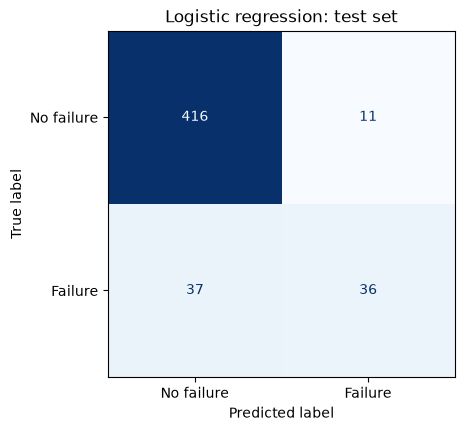

True Positives  (flagged & failed)       : 36
False Positives (flagged, but fine)      : 11
False Negatives (not flagged, but failed): 37
True Negatives  (not flagged & fine)     : 416


In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, pred_lr)
ConfusionMatrixDisplay(cm, display_labels=["No failure", "Failure"]).plot(cmap="Blues", colorbar=False)
plt.title("Logistic regression: test set")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Positives  (flagged & failed)       : {tp}")
print(f"False Positives (flagged, but fine)      : {fp}")
print(f"False Negatives (not flagged, but failed): {fn}")
print(f"True Negatives  (not flagged & fine)     : {tn}")

In [6]:
# One real example device from each cell
view = X_test.copy()
view["risk"] = log_reg.predict_proba(X_test)[:, 1].round(2)
view["predicted"] = pred_lr
view["actual"] = y_test.values
view["cell"] = np.select(
    [(view.predicted == 1) & (view.actual == 1), (view.predicted == 1) & (view.actual == 0),
     (view.predicted == 0) & (view.actual == 1)],
    ["TP", "FP", "FN"], default="TN")
cols = ["cell", "device_type", "age_years", "avg_temp_c", "crash_count_90d", "risk", "predicted", "actual"]
view.groupby("cell").head(1)[cols].set_index("cell").loc[["TP", "FP", "FN", "TN"]]

,device_type,age_years,avg_temp_c,crash_count_90d,risk,predicted,actual
cell,,,,,,,
TP,Switch,5.2,44.0,3,0.57,1,1
FP,Router,9.8,51.9,2,0.90,1,0
FN,Router,2.2,49.5,1,0.09,0,1
TN,Switch,7.3,42.3,0,0.03,0,0


## 3.2 Accuracy and the Accuracy Paradox

In [7]:
from sklearn.metrics import accuracy_score

print(f"Share of devices that failed (base rate): {y_test.mean():.1%}")
print(f"Baseline 'always no failure' accuracy:     {accuracy_score(y_test, baseline.predict(X_test)):.1%}")
print(f"Logistic regression accuracy:              {accuracy_score(y_test, pred_lr):.1%}")
print(f"  ... check by hand: (TP + TN) / total =   ({tp} + {tn}) / {len(y_test)} = {(tp + tn) / len(y_test):.1%}")

Share of devices that failed (base rate): 14.6%
Baseline 'always no failure' accuracy:     85.4%
Logistic regression accuracy:              90.4%
  ... check by hand: (TP + TN) / total =   (36 + 416) / 500 = 90.4%


**What to say:** "The do-nothing baseline is about 85% accurate and catches **zero** failures. Our model is only a few points better on accuracy, but it's a completely different business outcome. That's why we need more metrics."

## 3.3 Precision, Recall and Specificity

In [8]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)
specificity = tn / (tn + fp)

print(f"Precision   = TP / (TP + FP) = {tp} / {tp + fp} = {precision:.1%}"
      "   -> of the truck-rolls we send, how many were really needed?")
print(f"Recall      = TP / (TP + FN) = {tp} / {tp + fn} = {recall:.1%}"
      "   -> of the devices that failed, how many did we catch in time?")
print(f"Specificity = TN / (TN + FP) = {tn} / {tn + fp} = {specificity:.1%}"
      "   -> of the healthy devices, how many did we correctly leave alone?")

Precision   = TP / (TP + FP) = 36 / 47 = 76.6%   -> of the truck-rolls we send, how many were really needed?
Recall      = TP / (TP + FN) = 36 / 73 = 49.3%   -> of the devices that failed, how many did we catch in time?
Specificity = TN / (TN + FP) = 416 / 427 = 97.4%   -> of the healthy devices, how many did we correctly leave alone?


In [9]:
from sklearn.metrics import classification_report
print(classification_report(y_test, pred_lr, target_names=["No failure", "Failure"]))

              precision    recall  f1-score   support

  No failure       0.92      0.97      0.95       427
     Failure       0.77      0.49      0.60        73

    accuracy                           0.90       500
   macro avg       0.84      0.73      0.77       500
weighted avg       0.90      0.90      0.90       500



**What to say:** "Read the 'Failure' row: precision is high (when we roll a truck it's usually needed), but recall is under half: we're still missing more than half the failures. For an outage-prevention programme, that's the number the ops manager will care about."

## 3.4 F1-Score

In [10]:
from sklearn.metrics import f1_score

f1 = 2 * precision * recall / (precision + recall)
print(f"F1 = 2 x P x R / (P + R) = {f1:.2f}   (sklearn: {f1_score(y_test, pred_lr):.2f})")
print(f"Simple average of P and R would be {(precision + recall) / 2:.2f}; F1 is pulled down by the weaker one.")

F1 = 2 x P x R / (P + R) = 0.60   (sklearn: 0.60)
Simple average of P and R would be 0.63; F1 is pulled down by the weaker one.


In [11]:
# Side-by-side: all three models at the default 0.5 threshold
from sklearn.metrics import precision_score, recall_score

rows = []
for name, model in [("Baseline", baseline), ("Logistic regression", log_reg), ("KNN (K=5)", knn)]:
    p = model.predict(X_test)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, p),
                 "precision": precision_score(y_test, p, zero_division=0),
                 "recall": recall_score(y_test, p),
                 "f1": f1_score(y_test, p)})
pd.DataFrame(rows).round(2)

,model,accuracy,precision,recall,f1
0,Baseline,0.85,0.00,0.00,0.00
1,Logistic regression,0.90,0.77,0.49,0.60
2,KNN (K=5),0.88,0.65,0.33,0.44


## 3.5 ROC Curve and AUC
Every metric so far used one threshold (0.5). The ROC curve shows **every** threshold at once.

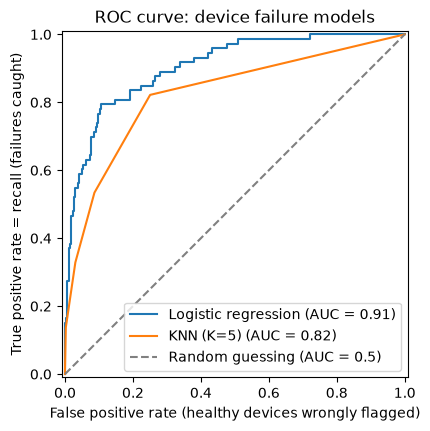

AUC logistic regression: 0.91
AUC KNN:                 0.82


In [12]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

ax = plt.gca()
RocCurveDisplay.from_estimator(log_reg, X_test, y_test, name="Logistic regression", ax=ax)
RocCurveDisplay.from_estimator(knn, X_test, y_test, name="KNN (K=5)", ax=ax)
ax.plot([0, 1], [0, 1], "--", c="grey", label="Random guessing (AUC = 0.5)")
ax.set_xlabel("False positive rate (healthy devices wrongly flagged)")
ax.set_ylabel("True positive rate = recall (failures caught)")
ax.legend(); plt.title("ROC curve: device failure models"); plt.show()

auc_lr = roc_auc_score(y_test, log_reg.predict_proba(X_test)[:, 1])
auc_knn = roc_auc_score(y_test, knn.predict_proba(X_test)[:, 1])
print(f"AUC logistic regression: {auc_lr:.2f}")
print(f"AUC KNN:                 {auc_knn:.2f}")

In [13]:
# AUC in plain English: pick one failed and one healthy device at random. How often does the model rank the failed one as riskier?
rng = np.random.default_rng(0)
risk = log_reg.predict_proba(X_test)[:, 1]
failed_risk, healthy_risk = risk[y_test.values == 1], risk[y_test.values == 0]
wins = (rng.choice(failed_risk, 10000) > rng.choice(healthy_risk, 10000)).mean()
print(f"Failed device ranked riskier in {wins:.0%} of 10,000 random pairs (close to the AUC)")

Failed device ranked riskier in 91% of 10,000 random pairs (close to the AUC)


**What to say:** "Logistic regression's curve hugs the top-left more than KNN's. AUC around 0.9 means: pick one failed and one healthy device, and nine times out of ten the model says the failed one is riskier. AUC is great for **comparing models**; the confusion matrix and precision/recall tell you what happens **at the threshold you actually use**."